# Steel Plant Electricity Usage Analysis and Prediction
**Course:** INT234 Predictive Analytics | **Assessment:** CA2 Skill Based Assessment
**Dataset:** Steel Industry Energy Consumption (UCI / Kaggle / Mendeley), 35,040 readings taken every 15 minutes in 2018

## Objectives
1. Check whether Light, Medium and Maximum load periods really use different amounts of energy.
2. Check whether weekends use less energy than weekdays.
3. Find the busiest hours of the day and the busiest months.
4. Find how reactive power and power factor are related to energy usage.
5. Predict the energy usage (kWh) using 4 machine learning models and find the best model.

**How to run:** click **Run All** at the top. The graphs appear below the cells. A copy of every graph is also saved in the `visualizations` folder.

## 1. Import libraries

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# find the project folder (works if you open the notebook from the notebooks folder or the main folder)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "visualizations"; RES = ROOT / "results"; MOD = ROOT / "models"
for folder in (FIG, RES, MOD):
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
COLORS = {"Light_Load": "#4C9F70", "Medium_Load": "#E9A23B", "Maximum_Load": "#D1495B"}
R = {}          # all numbers used in the report are collected here
FIGS = []       # list of saved graphs

def save_fig(name, caption):
    plt.tight_layout()
    plt.savefig(FIG / (name + ".png"), dpi=130, bbox_inches="tight")
    FIGS.append({"file": name + ".png", "caption": caption})
    plt.show()

## 2. Load the dataset

In [2]:
raw = pd.read_csv(ROOT / "data" / "Steel_industry_data.csv")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  str    
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  str    
 9   Day_of_week                           35040 non-null  str    
 10  Load_Type                             35040 non-null  str    
dtypes: float64(6), int64(1), s

In [4]:
raw.describe().round(2)

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.00,35040.00,35040.00,35040.00,35040.00,35040.00,35040.00
mean,27.39,13.04,3.87,0.01,80.58,84.37,42750.00
std,33.44,16.31,7.42,0.02,18.92,30.46,24940.53
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,3.20,2.30,0.00,0.00,63.32,99.70,21375.00
50%,4.57,5.00,0.00,0.00,87.96,100.00,42750.00
75%,51.24,22.64,2.09,0.02,99.02,100.00,64125.00
max,157.18,96.91,27.76,0.07,100.00,100.00,85500.00


## 3. Data cleaning
The CA asks for missing values, duplicates and inconsistent data. I check each one below.

In [5]:
df = raw.copy()
log = []     # small table that records every cleaning step

# 3.1 rename the columns so they are short and easy to type
df.columns = ["date", "usage_kwh", "lag_reactive", "lead_reactive", "co2", "lag_pf", "lead_pf",
              "nsm", "week_status", "day_of_week", "load_type"]
log.append(["Rename columns", "Gave short names to all 11 columns", 11])

# 3.2 missing values
missing = int(df.isna().sum().sum())
print("Missing values:", missing)
log.append(["Missing values", "Checked with isna()", missing])

# 3.3 duplicate rows
dups = int(df.duplicated().sum())
print("Duplicate rows:", dups)
log.append(["Duplicate rows", "Checked with duplicated()", dups])

Missing values: 0
Duplicate rows: 0


In [6]:
# 3.4 the date column is text, so I convert it to a real date and time
df["timestamp"] = pd.to_datetime(df["date"], format="%d/%m/%Y %H:%M")
print("Is the data in time order?", df["timestamp"].is_monotonic_increasing)

# nsm means 'number of seconds from midnight'. When nsm is 0 the reading is the 12 AM reading,
# which closes the day. But the file gives it the SAME day. Example: the last row says 31/12/2018 00:00.
midnight = df["nsm"] == 0
print("Midnight rows with the wrong day:", int(midnight.sum()))
print("Before fixing, last 3 rows:")
df[["date", "nsm"]].tail(3)

Is the data in time order? False
Midnight rows with the wrong day: 365
Before fixing, last 3 rows:


,date,nsm
35037,31/12/2018 23:30,84600
35038,31/12/2018 23:45,85500
35039,31/12/2018 00:00,0


In [7]:
# Fix: move every midnight reading to the next day and sort by time
df.loc[midnight, "timestamp"] = df.loc[midnight, "timestamp"] + pd.Timedelta(days=1)
df = df.sort_values("timestamp").reset_index(drop=True)

gaps = int((df["timestamp"].diff().dropna() != pd.Timedelta(minutes=15)).sum())
print("In time order now:", df["timestamp"].is_monotonic_increasing)
print("Gaps in the 15 minute series:", gaps)
print("First reading:", df["timestamp"].min(), "| Last reading:", df["timestamp"].max())
log.append(["Wrong dates (inconsistent data)", "Moved midnight readings to the correct day and sorted", int(midnight.sum())])
R["midnight_fixed"] = int(midnight.sum()); R["gaps_after_fix"] = gaps

In time order now: True
Gaps in the 15 minute series: 0
First reading: 2018-01-01 00:15:00 | Last reading: 2019-01-01 00:00:00


In [8]:
# 3.5 check that the labels and values make sense
reading_time = df["timestamp"] - pd.Timedelta(minutes=15)       # the time at which the reading period started
day_mismatch = int((reading_time.dt.day_name() != df["day_of_week"]).sum())
weekend_mismatch = int(((reading_time.dt.dayofweek >= 5) != (df["week_status"] == "Weekend")).sum())
print("Day name wrong:", day_mismatch, "| Weekend label wrong:", weekend_mismatch)
log.append(["Day and weekend labels", "Compared with the real calendar", day_mismatch + weekend_mismatch])

bad_pf = int(((df[["lag_pf", "lead_pf"]] < 0) | (df[["lag_pf", "lead_pf"]] > 100)).sum().sum())
negative = int((df[["usage_kwh", "lag_reactive", "lead_reactive", "co2"]] < 0).sum().sum())
print("Power factor outside 0 to 100:", bad_pf, "| Negative energy values:", negative)
log.append(["Impossible values", "Power factor outside 0-100 or negative energy", bad_pf + negative])

zero_row = df[(df["usage_kwh"] == 0) & (df["lag_pf"] == 0)]
print("Rows with usage 0 and power factor 0:", len(zero_row))
log.append(["Possible meter failure", "One row with usage 0 and power factor 0, kept it", len(zero_row)])

Day name wrong: 0 | Weekend label wrong: 0
Power factor outside 0 to 100: 0 | Negative energy values: 0
Rows with usage 0 and power factor 0: 1


In [9]:
# 3.6 outliers using the IQR rule
rows = []
for col in ["usage_kwh", "lag_reactive", "lead_reactive", "lag_pf", "lead_pf"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append([col, round(low, 2), round(high, 2), count, round(100 * count / len(df), 2)])
outliers = pd.DataFrame(rows, columns=["column", "lower_limit", "upper_limit", "outliers", "percent"])
R["outliers"] = outliers.to_dict("records")
log.append(["Outliers", "Checked with the IQR rule, kept them because they are real values", int(outliers["outliers"].sum())])
outliers

,column,lower_limit,upper_limit,outliers,percent
0,usage_kwh,-68.86,123.29,328,0.94
1,lag_reactive,-28.21,53.15,1059,3.02
2,lead_reactive,-3.13,5.22,7759,22.14
3,lag_pf,9.77,152.58,1,0.00
4,lead_pf,99.25,100.45,8327,23.76


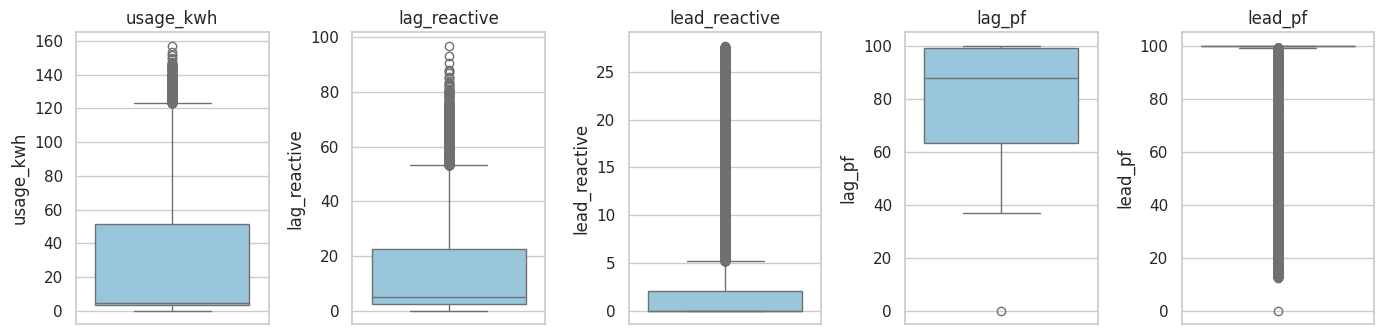

In [10]:
# Graph 1: box plots to see the outliers
fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, col in zip(axes, ["usage_kwh", "lag_reactive", "lead_reactive", "lag_pf", "lead_pf"]):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
save_fig("fig01_boxplots", "Box plots of the main numeric columns to check outliers")

**What this graph shows:** each box shows where most of the values lie. The dots outside the box are outliers.
The high usage dots are real busy periods of the plant, so I did not remove them. The leading columns show many dots only because most of their values are exactly 0 or 100.

In [11]:
cleaning_log = pd.DataFrame(log, columns=["step", "what_I_did", "items_affected"])
R["cleaning_log"] = cleaning_log.to_dict("records")
cleaning_log

,step,what_I_did,items_affected
0,Rename columns,Gave short names to all 11 columns,11
1,Missing values,Checked with isna(),0
2,Duplicate rows,Checked with duplicated(),0
3,Wrong dates (inconsistent data),Moved midnight readings to the correct day and...,365
4,Day and weekend labels,Compared with the real calendar,0
5,Impossible values,Power factor outside 0-100 or negative energy,0
6,Possible meter failure,"One row with usage 0 and power factor 0, kept it",1
7,Outliers,"Checked with the IQR rule, kept them because t...",17474


## 4. Feature engineering
I made new columns from the date and from the electrical readings. These help in the analysis and in the models.

In [12]:
reading_time = df["timestamp"] - pd.Timedelta(minutes=15)
df["hour"] = reading_time.dt.hour                       # hour of the day (0 to 23)
df["month"] = reading_time.dt.month                     # month number
df["dow_num"] = reading_time.dt.dayofweek               # Monday = 0 ... Sunday = 6
df["is_weekend"] = (df["dow_num"] >= 5).astype(int)     # 1 for Saturday and Sunday
df["shift"] = np.select([df["hour"].between(6, 13), df["hour"].between(14, 21)], ["Morning", "Evening"], default="Night")
df["total_reactive"] = df["lag_reactive"] + df["lead_reactive"]
df["avg_pf"] = (df["lag_pf"] + df["lead_pf"]) / 2

df.to_csv(ROOT / "data" / "cleaned_steel_data.csv", index=False)
R["clean_rows"], R["clean_cols"] = int(df.shape[0]), int(df.shape[1])
df[["timestamp", "usage_kwh", "hour", "month", "is_weekend", "shift", "total_reactive", "avg_pf"]].head()

,timestamp,usage_kwh,hour,month,is_weekend,shift,total_reactive,avg_pf
0,2018-01-01 00:15:00,3.17,0,1,0,Night,2.95,86.605
1,2018-01-01 00:30:00,4.00,0,1,0,Night,4.46,83.385
2,2018-01-01 00:45:00,3.24,0,1,0,Night,3.28,85.140
3,2018-01-01 01:00:00,3.31,0,1,0,Night,3.56,84.045
4,2018-01-01 01:15:00,3.82,1,1,0,Night,4.50,82.360


## 5. Exploratory data analysis (EDA)

In [13]:
R["usage_stats"] = {"mean": float(df.usage_kwh.mean()), "median": float(df.usage_kwh.median()), "std": float(df.usage_kwh.std()),
                    "min": float(df.usage_kwh.min()), "max": float(df.usage_kwh.max()), "total": float(df.usage_kwh.sum())}
R["load_counts"] = df["load_type"].value_counts().to_dict()
print(R["usage_stats"])
print(R["load_counts"])

{'mean': 27.386892408675802, 'median': 4.57, 'std': 33.44437970801512, 'min': 0.0, 'max': 157.18, 'total': 959636.7100000001}
{'Light_Load': 18072, 'Medium_Load': 9696, 'Maximum_Load': 7272}


/tmp/ipykernel_101/3972870806.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="load_type", order=["Light_Load", "Medium_Load", "Maximum_Load"], palette=COLORS, ax=axes[1])


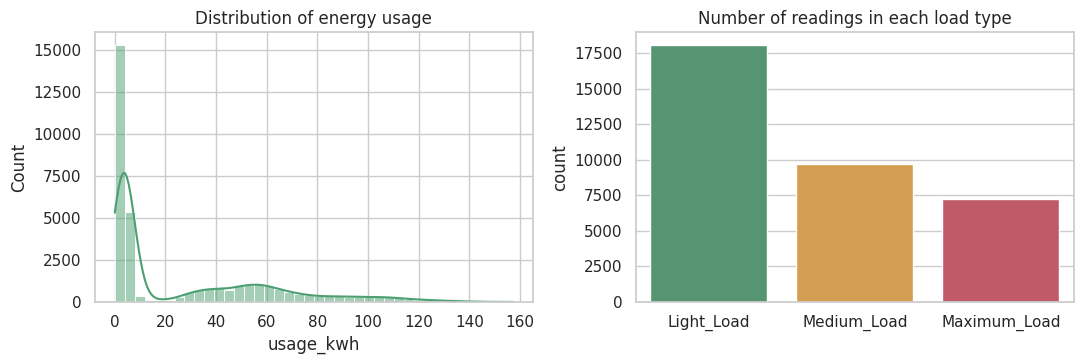

In [14]:
# Graph 2: how usage is spread and how many readings each load type has
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["usage_kwh"], bins=40, kde=True, color="#4C9F70", ax=axes[0])
axes[0].set_title("Distribution of energy usage"); axes[0].set_xlabel("usage_kwh")
sns.countplot(data=df, x="load_type", order=["Light_Load", "Medium_Load", "Maximum_Load"], palette=COLORS, ax=axes[1])
axes[1].set_title("Number of readings in each load type"); axes[1].set_xlabel("")
save_fig("fig02_distribution", "Distribution of energy usage and number of readings in each load type")

**What this graph shows:** the left graph shows that most readings have low usage and only some have very high usage (the data is right skewed).
The right graph shows that Light load is the biggest group, then Medium and then Maximum.

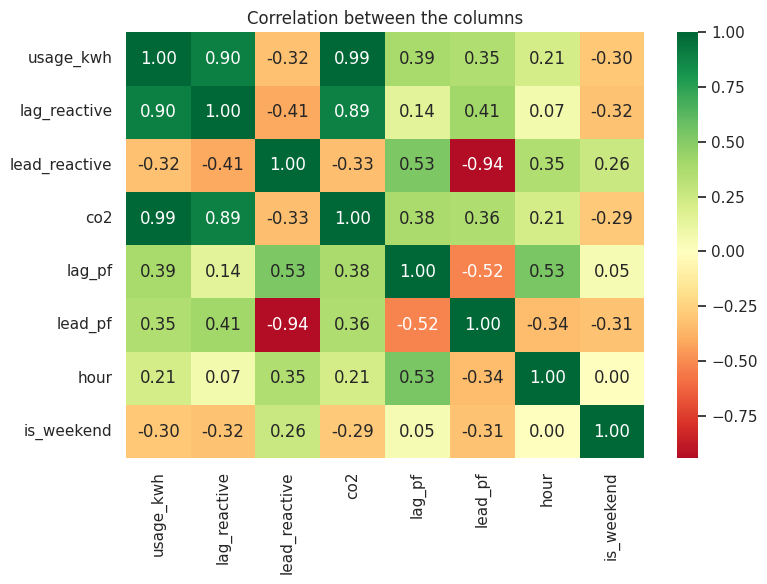

In [15]:
# Graph 3: correlation heatmap
cols = ["usage_kwh", "lag_reactive", "lead_reactive", "co2", "lag_pf", "lead_pf", "hour", "is_weekend"]
corr = df[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Correlation between the columns")
save_fig("fig03_correlation", "Correlation heatmap of the numeric columns")
R["corr_with_usage"] = corr["usage_kwh"].round(3).to_dict()

**What this graph shows:** a value close to +1 means two columns increase together, close to -1 means one goes up when the other goes down, and near 0 means no link.
Usage is strongly linked with `lag_reactive` and with `co2`. CO2 is calculated from usage, so I did **not** use it for prediction (it would give the answer away).

## 6. Objective 1: do the load types use different energy?
Test used: one-way ANOVA. H0 = all three load types have the same average usage. H1 = at least one is different.

In [16]:
order = ["Light_Load", "Medium_Load", "Maximum_Load"]
groups = [df.loc[df.load_type == k, "usage_kwh"] for k in order]
f_value, p_value = stats.f_oneway(*groups)
summary = df.groupby("load_type")["usage_kwh"].agg(["count", "mean", "median", "std", "min", "max"]).loc[order].round(2)
print("ANOVA F =", round(f_value, 1), "| p-value =", p_value)
R["o1"] = {"F": float(f_value), "p": float(p_value), "table": summary.reset_index().to_dict("records")}
summary

ANOVA F = 10787.8 | p-value = 0.0


,count,mean,median,std,min,max
load_type,,,,,,
Light_Load,18072,8.63,3.31,17.91,0.00,140.29
Medium_Load,9696,38.45,34.44,35.22,2.52,157.18
Maximum_Load,7272,59.27,56.63,29.75,2.92,151.67


/tmp/ipykernel_101/1490405176.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="load_type", y="usage_kwh", order=order, palette=COLORS)


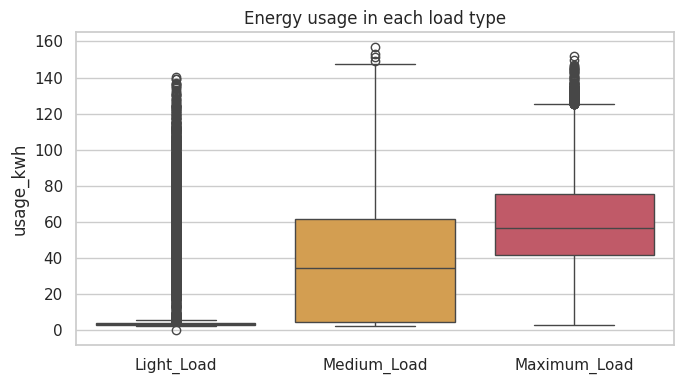

In [17]:
# Graph 4: usage for each load type
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="load_type", y="usage_kwh", order=order, palette=COLORS)
plt.title("Energy usage in each load type"); plt.xlabel("")
save_fig("fig04_load_type_usage", "Energy usage in Light, Medium and Maximum load periods")

**What this graph shows:** the middle line of each box is the median. The boxes go higher from Light to Medium to Maximum, so the load types really use different energy.
The p-value is far below 0.05, so I reject H0.

## 7. Objective 2: weekday and weekend
Test used: Welch t-test. H0 = average usage is the same on weekdays and weekends.

In [18]:
weekday = df.loc[df.week_status == "Weekday", "usage_kwh"]
weekend = df.loc[df.week_status == "Weekend", "usage_kwh"]
t_value, p_value = stats.ttest_ind(weekday, weekend, equal_var=False)
drop = 100 * (weekday.mean() - weekend.mean()) / weekday.mean()
print("Weekday average:", round(weekday.mean(), 2), "| Weekend average:", round(weekend.mean(), 2))
print("Weekend is", round(drop, 1), "% lower | t =", round(t_value, 2), "| p-value =", p_value)
R["o2"] = {"weekday_mean": float(weekday.mean()), "weekend_mean": float(weekend.mean()), "drop_pct": float(drop), "t": float(t_value), "p": float(p_value),
           "weekday_count": int(len(weekday)), "weekend_count": int(len(weekend))}

Weekday average: 33.62 | Weekend average: 11.73
Weekend is 65.1 % lower | t = 72.77 | p-value = 0.0


## 8. Objective 3: busiest hours and months

/tmp/ipykernel_101/679817692.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Weekday", "Weekend"], y=[weekday.mean(), weekend.mean()], palette=["#4C9F70", "#E9A23B"], ax=axes[0])


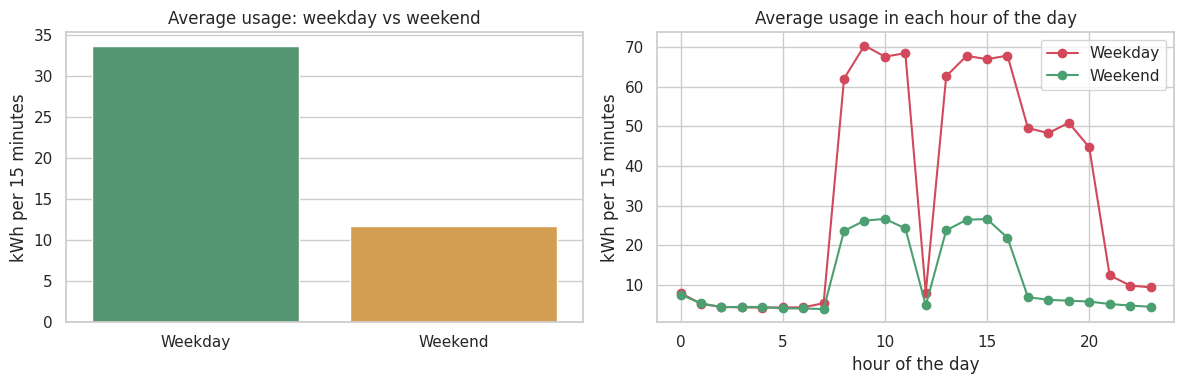

In [19]:
hourly = df.groupby(["hour", "week_status"])["usage_kwh"].mean().unstack()
hourly_all = df.groupby("hour")["usage_kwh"].mean()
monthly = df.groupby("month")["usage_kwh"].mean()
names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Graph 5: weekday vs weekend (bar) and average usage in every hour (line)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=["Weekday", "Weekend"], y=[weekday.mean(), weekend.mean()], palette=["#4C9F70", "#E9A23B"], ax=axes[0])
axes[0].set_title("Average usage: weekday vs weekend"); axes[0].set_ylabel("kWh per 15 minutes")
axes[1].plot(hourly.index, hourly["Weekday"], marker="o", label="Weekday", color="#D1495B")
axes[1].plot(hourly.index, hourly["Weekend"], marker="o", label="Weekend", color="#4C9F70")
axes[1].set_title("Average usage in each hour of the day"); axes[1].set_xlabel("hour of the day"); axes[1].set_ylabel("kWh per 15 minutes"); axes[1].legend()
save_fig("fig05_weekday_hour", "Weekday and weekend usage, and average usage in each hour")

**What this graph shows:** the bars show that weekends use much less energy. The line shows usage by hour. It is low at night, goes up in the morning,
drops suddenly at 12 (probably the lunch break) and stays high until evening on weekdays. On weekends it stays low all day.

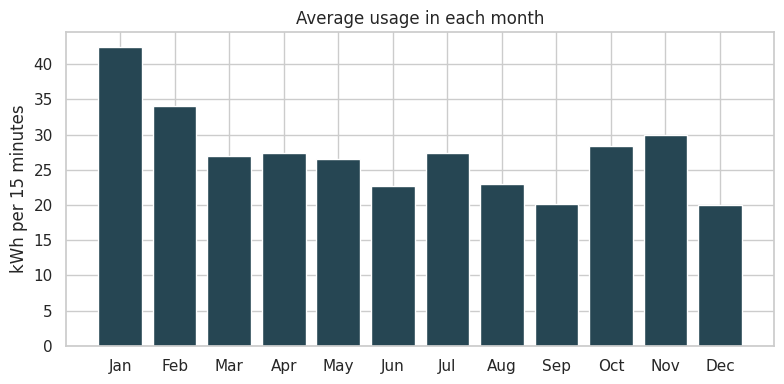

Busiest hour: 9 | Quietest hour: 5
Busiest month: Jan | Quietest month: Dec
{'Evening': 40.26, 'Morning': 36.07, 'Night': 5.84}


In [20]:
# Graph 6: average usage in each month
plt.figure(figsize=(8, 4))
plt.bar(names, monthly.values, color="#264653")
plt.title("Average usage in each month"); plt.ylabel("kWh per 15 minutes")
save_fig("fig06_monthly", "Average energy usage in each month of 2018")

R["o3"] = {"peak_hour": int(hourly_all.idxmax()), "peak_hour_value": float(hourly_all.max()),
           "low_hour": int(hourly_all.idxmin()), "low_hour_value": float(hourly_all.min()),
           "noon_value": float(hourly_all[12]), "eleven_value": float(hourly_all[11]),
           "peak_month": names[int(monthly.idxmax()) - 1], "peak_month_value": float(monthly.max()),
           "low_month": names[int(monthly.idxmin()) - 1], "low_month_value": float(monthly.min()),
           "shift": df.groupby("shift")["usage_kwh"].mean().round(2).to_dict(),
           "hourly": {int(k): round(float(v), 2) for k, v in hourly_all.items()},
           "monthly": {names[int(k) - 1]: round(float(v), 2) for k, v in monthly.items()}}
print("Busiest hour:", R["o3"]["peak_hour"], "| Quietest hour:", R["o3"]["low_hour"])
print("Busiest month:", R["o3"]["peak_month"], "| Quietest month:", R["o3"]["low_month"])
print(R["o3"]["shift"])

**What this graph shows:** each bar is the average usage of one month. January is the highest and December is the lowest.
Since I have only one year of data, I cannot say if this pattern repeats every year.

## 9. Objective 4: reactive power, power factor and usage

In [21]:
r_lag = df["usage_kwh"].corr(df["lag_reactive"])
r_lead = df["usage_kwh"].corr(df["lead_reactive"])
r_pf = df["usage_kwh"].corr(df["lag_pf"])
r_co2 = df["usage_kwh"].corr(df["co2"])
print("usage vs lag_reactive:", round(r_lag, 3))
print("usage vs lead_reactive:", round(r_lead, 3))
print("usage vs lag_pf:", round(r_pf, 3))
print("usage vs co2:", round(r_co2, 3))
df["pf_group"] = np.select([df["lag_pf"] < 70, df["lag_pf"] < 90], ["Poor (below 70)", "Fair (70 to 90)"], default="Good (90 and above)")
pf_table = df.groupby("pf_group")["usage_kwh"].agg(["count", "mean"]).round(2)
R["o4"] = {"r_lag": float(r_lag), "r_lead": float(r_lead), "r_pf": float(r_pf), "r_co2": float(r_co2), "pf_table": pf_table.reset_index().to_dict("records")}
pf_table

usage vs lag_reactive: 0.896
usage vs lead_reactive: -0.325
usage vs lag_pf: 0.386
usage vs co2: 0.988


,count,mean
pf_group,,
Fair (70 to 90),8479,42.32
Good (90 and above),15833,35.50
Poor (below 70),10728,3.61


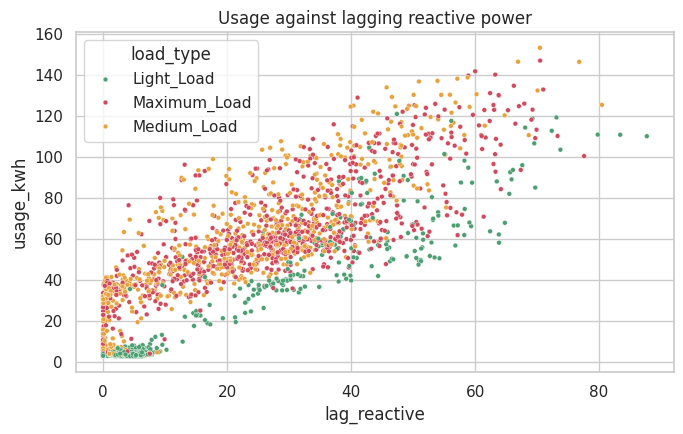

In [22]:
# Graph 7: usage against lagging reactive power
sample = df.sample(4000, random_state=42)
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=sample, x="lag_reactive", y="usage_kwh", hue="load_type", palette=COLORS, s=12)
plt.title("Usage against lagging reactive power")
save_fig("fig07_scatter", "Energy usage against lagging reactive power")

**What this graph shows:** every dot is one reading. The dots go up from left to right, so when reactive power is higher the usage is also higher (correlation about 0.9).
The colours show that Maximum load readings are mostly on the upper right side.

## 10. Objective 5: predict energy usage with machine learning
I selected 4 regression models from the syllabus: **Multiple Linear Regression, Polynomial Regression, Decision Tree and Random Forest**.

I did not use `co2` as an input because it is calculated from usage. I also did not use `load_type` because it is decided from the load itself.

In [23]:
features = ["lag_reactive", "lead_reactive", "lag_pf", "lead_pf", "hour", "month", "dow_num", "is_weekend", "total_reactive", "avg_pf"]
X = df[features]
y = df["usage_kwh"]

# 80 percent of the rows for training and 20 percent for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
R["split"] = {"train": int(len(X_train)), "test": int(len(X_test)), "features": features}

Training rows: 28032 | Testing rows: 7008


In [24]:
models = {
    "Multiple Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Polynomial Regression (degree 2)": make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)                     # learn from the training data
    pred = model.predict(X_test)                    # predict the test data
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, pred),
                    "MSE": mse,
                    "RMSE": np.sqrt(mse),
                    "Test R2": r2_score(y_test, pred),
                    "Train R2": r2_score(y_train, model.predict(X_train))})

results = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
best_name = results.loc[0, "Model"]
print("Best model:", best_name)
R["o5"] = {"table": results.round(4).to_dict("records"), "best": best_name}
results.round(4)

Best model: Random Forest


,Model,MAE,MSE,RMSE,Test R2,Train R2
0,Random Forest,0.2499,0.4939,0.7028,0.9996,0.9999
1,Decision Tree,1.1497,5.2532,2.2920,0.9954,0.9968
2,Polynomial Regression (degree 2),2.9168,20.5940,4.5381,0.9819,0.9822
3,Multiple Linear Regression,7.0718,100.8957,10.0447,0.9112,0.9138


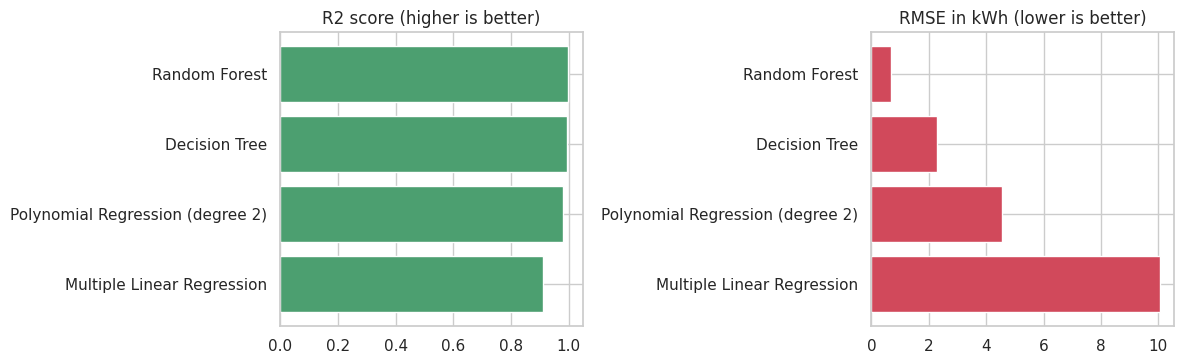

In [25]:
# Graph 8: compare the 4 models
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order_models = results.sort_values("Test R2")
axes[0].barh(order_models["Model"], order_models["Test R2"], color="#4C9F70"); axes[0].set_title("R2 score (higher is better)"); axes[0].set_xlim(0, 1.05)
axes[1].barh(order_models["Model"], order_models["RMSE"], color="#D1495B"); axes[1].set_title("RMSE in kWh (lower is better)")
save_fig("fig08_model_comparison", "Comparison of the four regression models")

**What this graph shows:** the left graph compares the R2 score (1 is perfect). The right graph compares the average size of the error (RMSE). Random Forest has the highest R2 and the lowest error, so it is the best model.

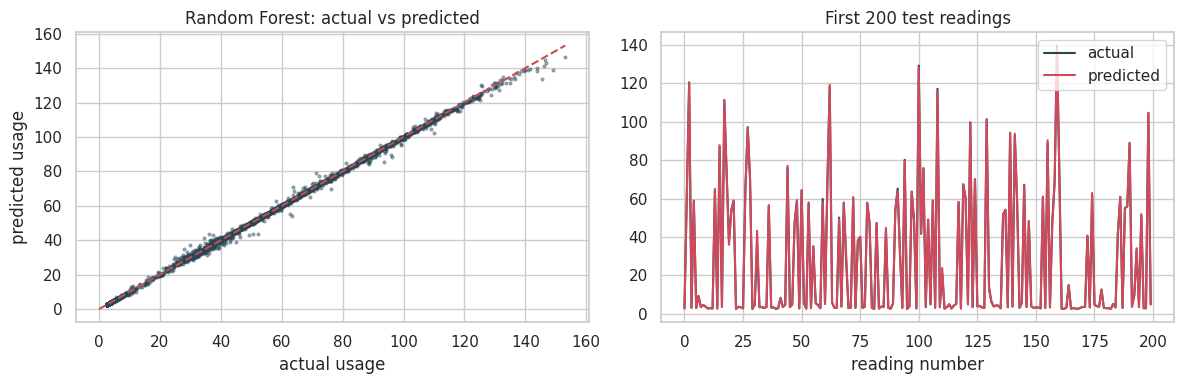

In [26]:
# Graph 9: actual and predicted values of the best model
best_pred = predictions[best_name]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, best_pred, s=4, alpha=0.4, color="#264653")
limit = [0, max(y_test.max(), best_pred.max())]
axes[0].plot(limit, limit, "r--"); axes[0].set_xlabel("actual usage"); axes[0].set_ylabel("predicted usage"); axes[0].set_title(best_name + ": actual vs predicted")
axes[1].plot(y_test.values[:200], label="actual", color="#264653")
axes[1].plot(best_pred[:200], label="predicted", color="#D1495B")
axes[1].set_title("First 200 test readings"); axes[1].set_xlabel("reading number"); axes[1].legend()
save_fig("fig09_actual_vs_predicted", "Actual and predicted usage of the best model")

**What this graph shows:** if the model were perfect all the dots would lie on the red dotted line. They are almost on the line, and in the right graph the two lines almost overlap, so the predictions are very close to the real values.

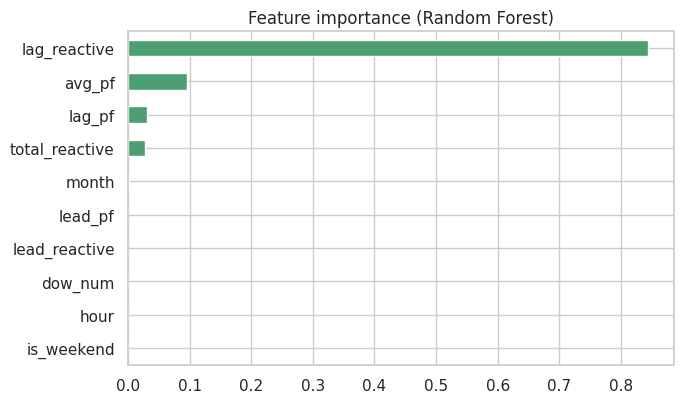

lag_reactive      0.8438
avg_pf            0.0954
lag_pf            0.0305
total_reactive    0.0277
month             0.0016
lead_pf           0.0005
lead_reactive     0.0003
dow_num           0.0001
hour              0.0001
is_weekend        0.0000
dtype: float64

In [27]:
# Graph 10: which inputs are most important for the Random Forest
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(7, 4.2))
importance.plot(kind="barh", color="#4C9F70")
plt.title("Feature importance (Random Forest)")
save_fig("fig10_feature_importance", "Feature importance of the Random Forest model")
R["o5"]["importance"] = importance.sort_values(ascending=False).round(4).to_dict()
importance.sort_values(ascending=False).round(4)

**What this graph shows:** a longer bar means the model depends more on that input. Lagging reactive power is by far the most important input.

**Why the score is so high:** in electrical theory the reactive power and the power factor are directly linked with the real power, so the model can almost calculate the usage from them. A very high score is therefore expected here.

## 11. Extra check on new months
In real life we want to predict months the model has not seen. So I trained on January to September and tested on October to December (without the month column).

In [28]:
train_part = df["month"] <= 9
test_part = ~train_part
X2 = X.drop(columns=["month"])
m1 = make_pipeline(StandardScaler(), LinearRegression()).fit(X2[train_part], y[train_part])
m2 = RandomForestRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X2[train_part], y[train_part])
check = []
for name, m in [("Multiple Linear Regression", m1), ("Random Forest", m2)]:
    p = m.predict(X2[test_part])
    check.append({"Model": name, "R2": r2_score(y[test_part], p), "MAE": mean_absolute_error(y[test_part], p), "RMSE": np.sqrt(mean_squared_error(y[test_part], p))})
check = pd.DataFrame(check).round(4)
R["o5"]["new_months"] = check.to_dict("records")
check

,Model,R2,MAE,RMSE
0,Multiple Linear Regression,0.9121,7.1875,9.4727
1,Random Forest,0.9996,0.2485,0.6767


## 12. Save the model and the results (used by the website)

In [29]:
# train the final Random Forest on all rows for the website
final_model = RandomForestRegressor(n_estimators=100, min_samples_leaf=4, n_jobs=-1, random_state=42).fit(X, y)
joblib.dump({"model": final_model, "features": features}, MOD / "usage_model.joblib", compress=3)

R["figures"] = FIGS
R["dataset"] = {"rows": int(len(df)), "start": str(df["timestamp"].min()), "end": str(df["timestamp"].max())}
R["raw_rows"], R["raw_cols"] = int(raw.shape[0]), int(raw.shape[1])
(RES / "results.json").write_text(json.dumps(R, indent=2, default=float))
results.round(4).to_csv(RES / "model_results.csv", index=False)
cleaning_log.to_csv(RES / "cleaning_log.csv", index=False)
print("Saved the model, results.json and", len(FIGS), "graphs")

Saved the model, results.json and 10 graphs


## 13. Conclusion
- The plant uses very different energy in the three load types, much less at weekends, and most energy in the day time on weekdays.
- Reactive power is strongly linked with usage.
- Random Forest was the best of the 4 models for predicting the usage.